DataFrame Clientes:
    ID_Cliente  Nombre  Edad Género   Ciudad Nivel_Educación Fecha_Registro
0         NaN    Bob0  56.0      F   Sydney        Maestría            NaT
1         2.0  Alice1  46.0      M   Berlín    Bachillerato     2020-02-10
2         3.0    Eve2  32.0    NaN      NaN        Maestría     2022-01-09
3         NaN  David3  60.0      M  Toronto    Bachillerato     2021-05-16
4         5.0  David4  25.0      M   Sydney        Maestría     2022-08-16

DataFrame Productos:
    ID_Producto Nombre_Producto    Categoría Subcategoría   Marca
0            1      Producto 1   Accesorios   Cargadores  Xiaomi
1            2      Producto 2   Accesorios   Cargadores   Apple
2            3      Producto 3  Videojuegos     Consolas  Lenovo
3            4      Producto 4   Accesorios   Cargadores    Sony
4            5      Producto 5        Audio  Auriculares  Lenovo

DataFrame Transacciones:
    ID_Transacción  ID_Cliente  ID_Producto Fecha_Transacción  Cantidad  \
0              

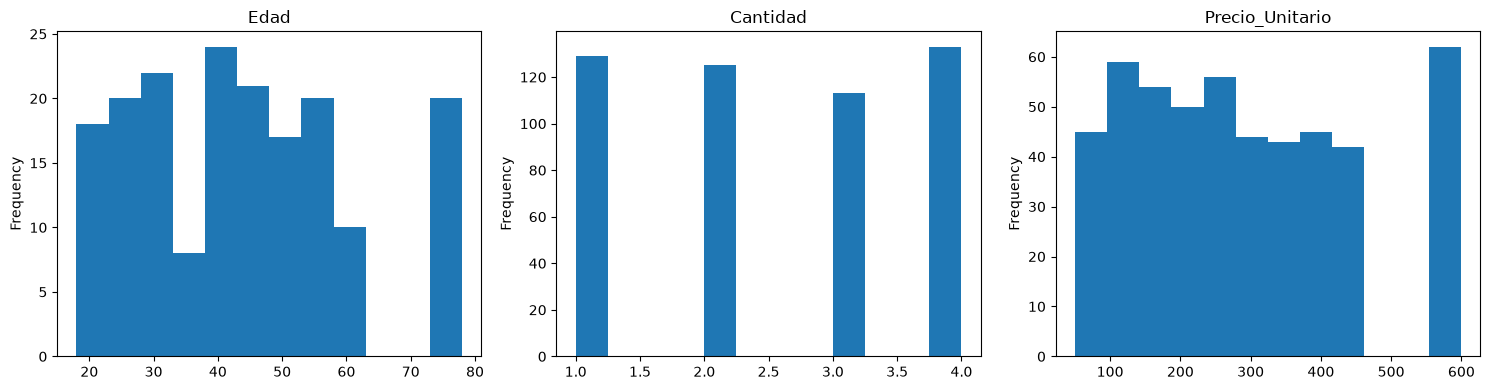

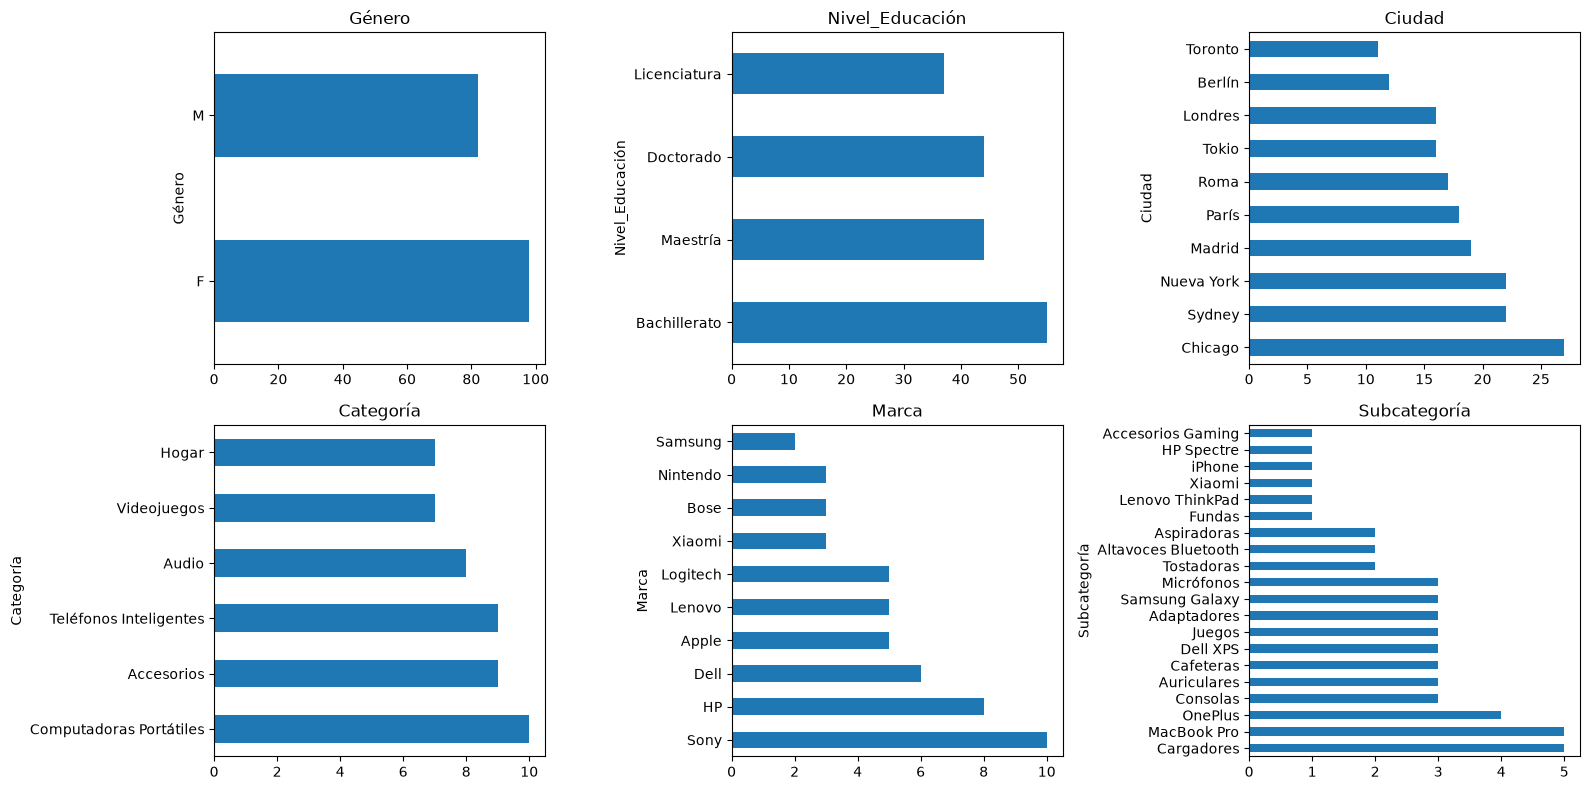

Clientes:
ID_Cliente         20
Nombre             20
Edad               20
Género             20
Ciudad             20
Nivel_Educación    20
Fecha_Registro     20
dtype: int64

Productos: 0
Transacciones: 0
Clientes con algún dato vacío: 105 de 200
Clientes completos: 95


In [1]:
import pandas as pd
import numpy as np
import random
import matplotlib.pyplot as plt

# Semilla para que los resultados no cambien en cada ejecución
random.seed(42)
np.random.seed(42)

# 1. Generación de Datos de Clientes

num_clientes = 200

nombres = ['Alice', 'Bob', 'Charlie', 'David', 'Eve', 'Finn', 'Grace', 'Henry', 'Ivy', 'Jack']
ciudades = ['Nueva York', 'Londres', 'París', 'Tokio', 'Sydney', 'Berlín', 'Madrid', 'Roma', 'Toronto', 'Chicago']
niveles_educacion = ['Bachillerato', 'Licenciatura', 'Maestría', 'Doctorado']
generos = ['M', 'F']

data_clientes = {
    'ID_Cliente': range(1, num_clientes + 1),
    'Nombre': [random.choice(nombres) + str(i) for i in range(num_clientes)],
    'Edad': np.random.randint(18, 65, num_clientes),
    'Género': np.random.choice(generos, num_clientes),
    'Ciudad': np.random.choice(ciudades, num_clientes),
    'Nivel_Educación': np.random.choice(niveles_educacion, num_clientes),
    'Fecha_Registro': pd.to_datetime(np.random.choice(pd.date_range('2020-01-01', '2023-12-31'), num_clientes))
}

df_clientes = pd.DataFrame(data_clientes)

# 2. Generación de Datos de Productos

num_productos = 50

categorias = ['Teléfonos Inteligentes', 'Computadoras Portátiles', 'Accesorios', 'Audio', 'Hogar', 'Videojuegos']
subcategorias = {
    'Teléfonos Inteligentes': ['iPhone', 'Samsung Galaxy', 'Xiaomi', 'OnePlus'],
    'Computadoras Portátiles': ['Dell XPS', 'MacBook Pro', 'HP Spectre', 'Lenovo ThinkPad'],
    'Accesorios': ['Cargadores', 'Fundas', 'Protectores de Pantalla', 'Adaptadores'],
    'Audio': ['Auriculares', 'Altavoces Bluetooth', 'Micrófonos'],
    'Hogar': ['Aspiradoras', 'Cafeteras', 'Tostadoras'],
    'Videojuegos': ['Consolas', 'Juegos', 'Accesorios Gaming']
}

marcas = ['Apple', 'Samsung', 'Dell', 'HP', 'Lenovo', 'Sony', 'Bose', 'Logitech', 'Xiaomi', 'Nintendo']

data_productos = {
    'ID_Producto': range(1, num_productos + 1),
    'Nombre_Producto': ['Producto ' + str(i) for i in range(1, num_productos + 1)],
    'Categoría': np.random.choice(categorias, num_productos),
}

# Ajustamos las subcategorías y marcas basándonos en la categoría seleccionada
data_productos['Subcategoría'] = [random.choice(subcategorias[cat]) for cat in data_productos['Categoría']]
data_productos['Marca'] = np.random.choice(marcas, num_productos)

df_productos = pd.DataFrame(data_productos)

# 3. Generación de Datos de Transacciones
num_transacciones = 500

data_transacciones = {
    'ID_Transacción': range(1, num_transacciones + 1),
    'ID_Cliente': np.random.choice(df_clientes['ID_Cliente'], num_transacciones),
    'ID_Producto': np.random.choice(df_productos['ID_Producto'], num_transacciones),
    'Fecha_Transacción': pd.to_datetime(np.random.choice(pd.date_range('2023-01-01', '2024-01-31'), num_transacciones)),
    'Cantidad': np.random.randint(1, 5, num_transacciones)
}
df_transacciones = pd.DataFrame(data_transacciones)

# Añadimos el precio unitario basándonos en el ID_Producto
df_transacciones = pd.merge(df_transacciones, df_productos[['ID_Producto']], on='ID_Producto', how='left')
df_transacciones['Precio_Unitario'] = np.random.randint(50, 500, num_transacciones)

# 4. Simulación de Valores Faltantes y Outliers
# a. Valores Faltantes (10% de los datos)
for columna in df_clientes.columns:
    indices_faltantes = random.sample(range(len(df_clientes)), int(0.1 * len(df_clientes)))
    df_clientes.loc[indices_faltantes, columna] = np.nan

# b. Outliers (en la columna 'Edad' y 'Precio_Unitario')
df_clientes['Edad'] = np.where(df_clientes['Edad'] > 60, np.random.randint(65, 80), df_clientes['Edad'])
df_transacciones['Precio_Unitario'] = np.where(df_transacciones['Precio_Unitario'] > 450, np.random.randint(500, 700), df_transacciones['Precio_Unitario'])

# Imprimimos los DataFrames para verificar
print("DataFrame Clientes:\n", df_clientes.head())
print("\nDataFrame Productos:\n", df_productos.head())
print("\nDataFrame Transacciones:\n", df_transacciones.head())

# Actividad 4. Medidas de tendencia central y dispersión

tabla = pd.DataFrame({
    'Edad': df_clientes['Edad'],
    'Cantidad': df_transacciones['Cantidad'],
    'Precio_Unitario': df_transacciones['Precio_Unitario']})

resumen = pd.DataFrame({
    'Media': tabla.mean(),
    'Mediana': tabla.median(),
    'Moda': tabla.mode().iloc[0],
    'Desv_est': tabla.std(),
    'Varianza': tabla.var(),
    'Mínimo': tabla.min(),
    'Máximo': tabla.max()})
resumen['Rango'] = resumen['Máximo'] - resumen['Mínimo']
print(resumen.T.round(2))

# Actividad 5. Histogramas

fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axs, tabla.columns):
    tabla[col].dropna().plot.hist(ax=ax, bins=12, title=col)
plt.tight_layout()
plt.show()

# Actividad 6. Diagramas de barras

cols = [(df_clientes, 'Género'), (df_clientes, 'Nivel_Educación'), (df_clientes, 'Ciudad'),
        (df_productos, 'Categoría'), (df_productos, 'Marca'), (df_productos, 'Subcategoría')]
fig, axs = plt.subplots(2, 3, figsize=(16, 8))
for ax, (d, c) in zip(axs.ravel(), cols):
    d[c].value_counts().plot.barh(ax=ax, title=c)
plt.tight_layout()
plt.show()

# Actividad 7. Valores faltantes

print('Clientes:')
print(df_clientes.isna().sum())
print('\nProductos:', df_productos.isna().sum().sum())
print('Transacciones:', df_transacciones.isna().sum().sum())


# Actividad 8. Impacto de los valores faltantes

print('Clientes con algún dato vacío:', df_clientes.isna().any(axis=1).sum(), 'de', len(df_clientes))
print('Clientes completos:', len(df_clientes.dropna()))
